# Predictive Analytics: NIFTY 50 Next-Day Market Direction Prediction
**Author:** Aditya Sindhwani  
**Course:** Predictive Analytics (CSE3141)  
**Problem type:** Binary classification using time-series data

## 1. Problem statement
The goal is to predict whether the NIFTY 50 index's next trading-day closing price will be higher than the current trading-day closing price.

- `1 = UP`: next close is greater than today's close
- `0 = DOWN / NOT UP`: next close is less than or equal to today's close

This is an educational classification exercise, **not financial advice or a reliable trading signal**. Stock-market direction is noisy and difficult to predict.

## 2. Install and import libraries
If `yfinance` is not installed in your environment, run `%pip install yfinance` in a separate notebook cell, then rerun the imports.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    ConfusionMatrixDisplay, RocCurveDisplay
)

import warnings
warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

## 3. Load the local CSV dataset
Download the NIFTY 50 historical CSV from the dataset source linked below. Save it as **`NIFTY50.csv` in the same folder as this notebook**. Then this notebook reads the file directly from your computer—no Yahoo Finance import or live download is used.

**Dataset source:** [NIFTY 50 Historical Data CSV on GitHub](https://github.com/Hareeshkesavan/Stock-Market-Dataset/blob/main/Nifty%2050%20Historical%20Data.csv)

The downloaded file has columns such as `Date`, `Price`, `Open`, `High`, `Low`, `Vol.`, and `Change %`. Here, `Price` represents the closing price, so the loader renames it to `Close`. The file is initially newest-first; the cleaning step later sorts it oldest-first for time-series modelling.

In [2]:
# Load the CSV file saved beside this notebook.
# If you saved it in another folder, provide the full path in read_csv().
df = pd.read_csv("Nifty 50 Historical Data.csv")

# Standardise column names from the downloaded source.
df.columns = [str(c).replace("\\ufeff", "").strip() for c in df.columns]
rename_map = {
    "Price": "Close",
    "Vol.": "Volume",
    "Change %": "Change_Pct"
}
df = df.rename(columns=rename_map)

# Convert volume strings such as '698.60M' or '250K' to numeric values.
def parse_volume(value):
    if pd.isna(value):
        return np.nan
    value = str(value).strip().replace(",", "")
    if value.endswith("B"):
        return float(value[:-1]) * 1_000_000_000
    if value.endswith("M"):
        return float(value[:-1]) * 1_000_000
    if value.endswith("K"):
        return float(value[:-1]) * 1_000
    try:
        return float(value)
    except ValueError:
        return np.nan

if "Volume" in df.columns:
    df["Volume"] = df["Volume"].apply(parse_volume)

print("Dataset loaded successfully.")
print("Shape:", df.shape)
display(df.head())


Dataset loaded successfully.
Shape: (2786, 7)


,Date,Close,Open,High,Low,Volume,Change_Pct
0,03/30/2026,"22,331.40","22,549.65","22,714.10","22,283.85",698600000.0,-2.14%
1,03/27/2026,"22,819.60","23,173.55","23,186.10","22,804.55",612560000.0,-2.09%
2,03/25/2026,"23,306.45","23,064.40","23,465.35","23,063.20",505420000.0,1.72%
3,03/24/2026,"22,912.40","22,878.45","23,057.30","22,624.20",538100000.0,1.78%
4,03/23/2026,"22,512.65","22,824.35","22,851.70","22,471.25",550280000.0,-2.60%


### Important: keep the CSV beside the notebook
The expected filename is **`NIFTY50.csv`**. If you choose a different filename or save it in another folder, update the path in `pd.read_csv(...)` accordingly. The downloaded source contains `Price` rather than `Close`; the loader handles this automatically.

## 4. Understand and clean the data
We inspect the first/last rows, dimensions, data types, missing values and duplicate records. We sort by date and convert numeric columns to numeric types. Weekends and exchange holidays are naturally absent from market data; we do not fill them with artificial observations.

In [3]:
display(df.head())
display(df.tail())
print("Dataset shape:", df.shape)
df.info()

,Date,Close,Open,High,Low,Volume,Change_Pct
0,03/30/2026,"22,331.40","22,549.65","22,714.10","22,283.85",698600000.0,-2.14%
1,03/27/2026,"22,819.60","23,173.55","23,186.10","22,804.55",612560000.0,-2.09%
2,03/25/2026,"23,306.45","23,064.40","23,465.35","23,063.20",505420000.0,1.72%
3,03/24/2026,"22,912.40","22,878.45","23,057.30","22,624.20",538100000.0,1.78%
4,03/23/2026,"22,512.65","22,824.35","22,851.70","22,471.25",550280000.0,-2.60%


,Date,Close,Open,High,Low,Volume,Change_Pct
2781,01/07/2015,"8,102.10","8,118.65","8,151.20","8,065.45",164080000.0,-0.31%
2782,01/06/2015,"8,127.35","8,325.30","8,327.85","8,111.35",172800000.0,-3.00%
2783,01/05/2015,"8,378.40","8,407.95","8,445.60","8,363.90",118160000.0,-0.20%
2784,01/02/2015,"8,395.45","8,288.70","8,410.60","8,288.70",101890000.0,1.35%
2785,01/01/2015,"8,284.00","8,272.80","8,294.70","8,248.75",56560000.0,0.02%


Dataset shape: (2786, 7)
<class 'pandas.DataFrame'>
RangeIndex: 2786 entries, 0 to 2785
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Date        2786 non-null   str    
 1   Close       2786 non-null   str    
 2   Open        2786 non-null   str    
 3   High        2786 non-null   str    
 4   Low         2786 non-null   str    
 5   Volume      2782 non-null   float64
 6   Change_Pct  2786 non-null   str    
dtypes: float64(1), str(6)
memory usage: 289.7 KB


In [4]:
# OHLC prices are required. Volume is optional because index datasets may not report it.
required_columns = ["Date", "Open", "High", "Low", "Close"]
missing_columns = [c for c in required_columns if c not in df.columns]
if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}. "
        "Check the downloaded CSV and its column names."
    )

if "Volume" not in df.columns:
    df["Volume"] = np.nan

df = df[["Date", "Open", "High", "Low", "Close", "Volume"]].copy()
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
for col in ["Open", "High", "Low", "Close", "Volume"]:
    df[col] = pd.to_numeric(df[col].astype(str).str.replace(",", "", regex=False), errors="coerce")

print("Missing values before cleaning:")
print(df.isnull().sum())
print("Duplicate rows before cleaning:", df.duplicated().sum())

Missing values before cleaning:
Date      0
Open      0
High      0
Low       0
Close     0
Volume    4
dtype: int64
Duplicate rows before cleaning: 0


In [5]:
# Clean the required price fields. Volume is kept only if it is genuinely available.
price_cols = ["Open", "High", "Low", "Close"]
df[price_cols] = df[price_cols].replace([np.inf, -np.inf], np.nan)
df["Volume"] = df["Volume"].replace([np.inf, -np.inf], np.nan)
df = df.dropna(subset=price_cols)

# If Volume is missing for the whole dataset or is always zero (common for index series),
# do not use it as a model feature.
use_volume = df["Volume"].notna().any() and (df["Volume"].fillna(0) > 0).any()
if use_volume:
    df["Volume"] = df["Volume"].fillna(0)
else:
    df = df.drop(columns=["Volume"])

# Basic sanity checks for impossible non-positive prices.
df = df[(df[price_cols] > 0).all(axis=1)]

print("Shape after cleaning:", df.shape)
print("Missing values after cleaning:")
print(df.isnull().sum())
print("Duplicate rows after cleaning:", df.duplicated().sum())
print("Volume feature available:", use_volume)
display(df.head())

Shape after cleaning: (2786, 6)
Missing values after cleaning:
Date      0
Open      0
High      0
Low       0
Close     0
Volume    0
dtype: int64
Duplicate rows after cleaning: 0
Volume feature available: True


,Date,Open,High,Low,Close,Volume
0,2026-03-30,22549.65,22714.10,22283.85,22331.40,698600000.0
1,2026-03-27,23173.55,23186.10,22804.55,22819.60,612560000.0
2,2026-03-25,23064.40,23465.35,23063.20,23306.45,505420000.0
3,2026-03-24,22878.45,23057.30,22624.20,22912.40,538100000.0
4,2026-03-23,22824.35,22851.70,22471.25,22512.65,550280000.0


## 5. Exploratory Data Analysis (EDA)
We visualise the closing-price trend, trading volume, daily returns and return outliers. Large moves may be genuine market events, so an IQR flag is used to inspect potential outliers rather than automatically deleting them.

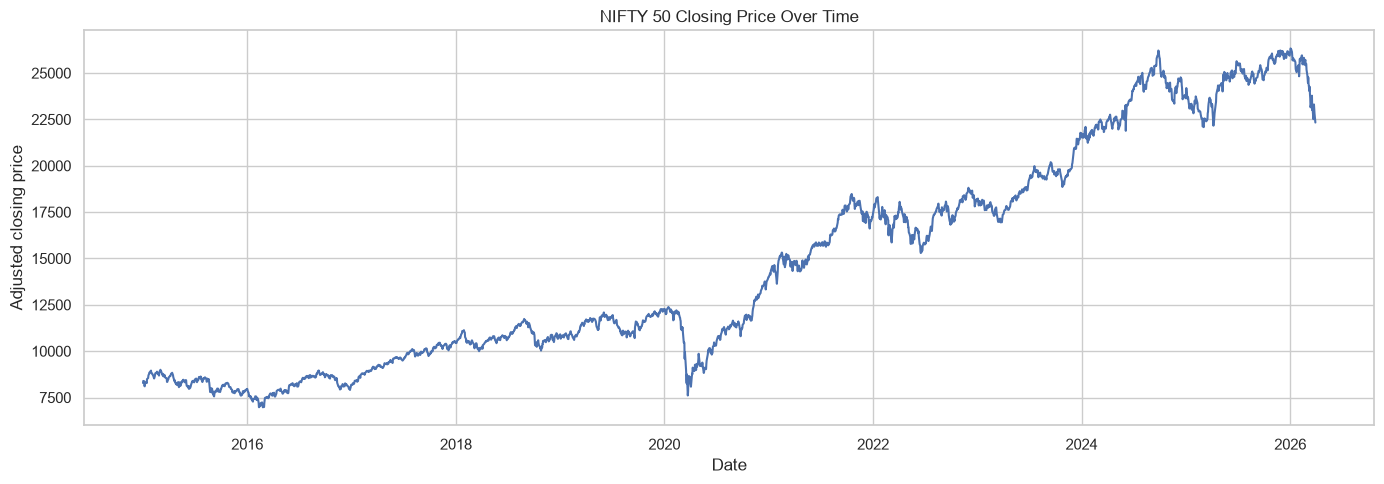

In [6]:
plt.figure(figsize=(14, 5))
plt.plot(df["Date"], df["Close"])
plt.title("NIFTY 50 Closing Price Over Time")
plt.xlabel("Date")
plt.ylabel("Adjusted closing price")
plt.tight_layout()
plt.show()

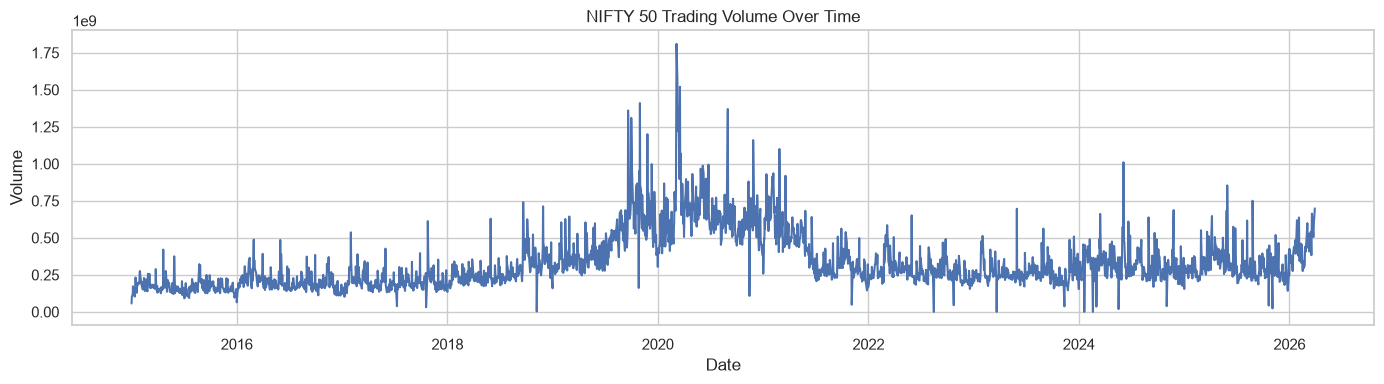

In [7]:
if "Volume" in df.columns:
    plt.figure(figsize=(14, 4))
    plt.plot(df["Date"], df["Volume"])
    plt.title("NIFTY 50 Trading Volume Over Time")
    plt.xlabel("Date")
    plt.ylabel("Volume")
    plt.tight_layout()
    plt.show()
else:
    print("Volume plot skipped: the index dataset does not provide usable volume values.")

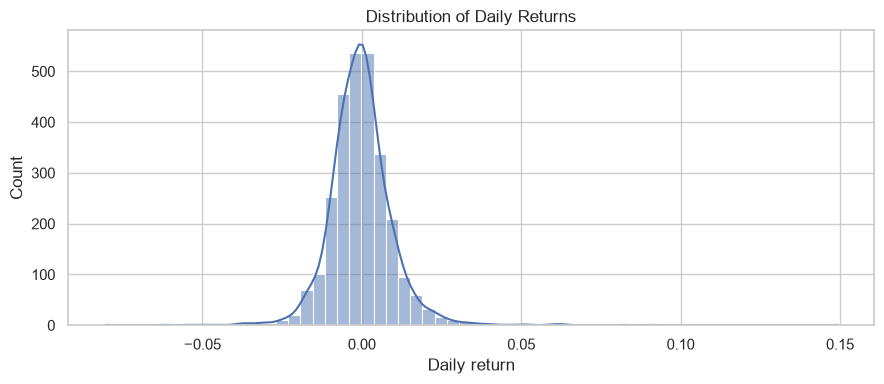

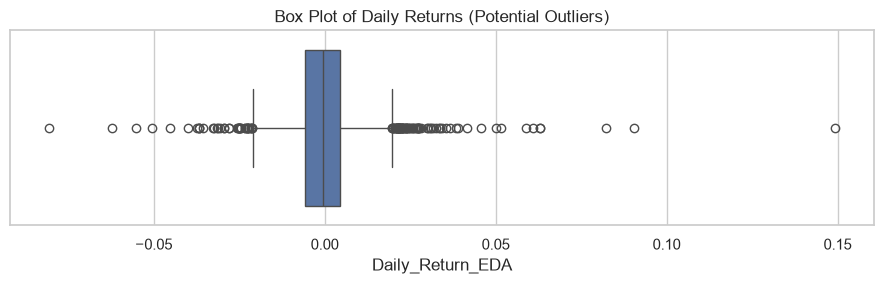

In [8]:
df["Daily_Return_EDA"] = df["Close"].pct_change()

plt.figure(figsize=(9, 4))
sns.histplot(df["Daily_Return_EDA"].dropna(), bins=60, kde=True)
plt.title("Distribution of Daily Returns")
plt.xlabel("Daily return")
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 3))
sns.boxplot(x=df["Daily_Return_EDA"].dropna())
plt.title("Box Plot of Daily Returns (Potential Outliers)")
plt.tight_layout()
plt.show()

In [9]:
display(df[["Open", "High", "Low", "Close", "Volume"]].describe())

returns = df["Close"].pct_change().dropna()
q1, q3 = returns.quantile([0.25, 0.75])
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr
outlier_mask = (returns < lower_bound) | (returns > upper_bound)

print("Potential daily-return outliers flagged by IQR:", int(outlier_mask.sum()))
print("These are inspected, not automatically deleted, because genuine market shocks can be important.")

,Open,High,Low,Close,Volume
count,2786.000000,2786.000000,2786.000000,2786.000000,2.786000e+03
mean,14746.438388,14813.128015,14657.367480,14736.474156,3.284597e+08
std,5862.120038,5884.104958,5838.562114,5861.772441,1.840413e+08
min,7023.650000,7034.200000,6825.800000,6970.600000,0.000000e+00
25%,9881.987500,9924.800000,9825.800000,9884.887500,2.074500e+08
50%,12027.325000,12074.900000,11950.100000,12015.225000,2.720550e+08
75%,18710.250000,18752.037500,18635.225000,18694.875000,3.905625e+08
max,26333.700000,26373.200000,26210.050000,26328.550000,1.810000e+09


Potential daily-return outliers flagged by IQR: 117
These are inspected, not automatically deleted, because genuine market shocks can be important.


## 6. Feature engineering and target creation
We create lagged returns, moving averages, rolling volatility, daily range and close-to-open movement. These features summarise information available by the end of the current trading day.

**Target:** whether the next trading day's close is higher than today's close. The final row has no known next-day target and is removed.

No future closing price is included among the input features.

In [10]:
df["Daily_Return"] = df["Close"].pct_change()
df["Return_Lag1"] = df["Daily_Return"].shift(1)
df["Return_Lag2"] = df["Daily_Return"].shift(2)
df["Return_Lag3"] = df["Daily_Return"].shift(3)

df["MA5"] = df["Close"].rolling(window=5).mean()
df["MA10"] = df["Close"].rolling(window=10).mean()
df["MA20"] = df["Close"].rolling(window=20).mean()

df["Volatility10"] = df["Daily_Return"].rolling(window=10).std()
df["Daily_Range_Pct"] = (df["High"] - df["Low"]) / df["Close"]
df["Open_Close_Pct"] = (df["Close"] - df["Open"]) / df["Open"]

feature_columns = [
    "Daily_Return", "Return_Lag1", "Return_Lag2", "Return_Lag3",
    "MA5", "MA10", "MA20", "Volatility10",
    "Daily_Range_Pct", "Open_Close_Pct"
]

# Include volume change only when real volume observations are available.
if "Volume" in df.columns:
    df["Volume_Change"] = df["Volume"].pct_change(fill_method=None)
    feature_columns.append("Volume_Change")

# Binary target: 1 if next close rises, otherwise 0.
df["Target"] = (df["Close"].shift(-1) > df["Close"]).astype(int)

# Replace infinite values (for example, volume percentage change after a zero-volume day)
# with NaN, then remove rows with invalid model features.
df.replace([np.inf, -np.inf], np.nan, inplace=True)

# Rolling windows and lagged variables create missing values at the beginning.
model_df = df.dropna(subset=feature_columns).copy()
model_df = model_df.iloc[:-1].copy()  # remove final row with unknown next-day direction

print("Model dataset shape:", model_df.shape)
print("Target distribution:")
print(model_df["Target"].value_counts())
print(model_df["Target"].value_counts(normalize=True).rename("proportion"))
display(model_df[["Date"] + feature_columns + ["Target"]].head())

print("Infinite values remaining in features:", np.isinf(model_df[feature_columns].to_numpy(dtype=float)).sum())
print("Missing values remaining in features:", model_df[feature_columns].isna().sum().sum())

Model dataset shape: (2762, 19)
Target distribution:
Target
0    1487
1    1275
Name: count, dtype: int64
Target
0    0.538378
1    0.461622
Name: proportion, dtype: float64


,Date,Daily_Return,Return_Lag1,Return_Lag2,Return_Lag3,MA5,MA10,MA20,Volatility10,Daily_Range_Pct,Open_Close_Pct,Volume_Change,Target
19,2026-02-27,0.012586,0.015735,-0.011524,0.012902,24748.24,24268.795,23672.7425,0.012879,0.013309,-0.011045,-0.154671,1
20,2026-02-26,0.012626,0.012586,0.015735,-0.011524,24957.46,24503.340,23831.0000,0.011185,0.006746,-0.002338,-0.076779,0
21,2026-02-25,-0.000551,0.012626,0.012586,0.015735,25100.78,24687.675,23964.1450,0.010837,0.008806,-0.001180,0.022185,0
22,2026-02-24,-0.002270,-0.000551,0.012626,0.012586,25289.61,24843.455,24070.0550,0.011234,0.012358,-0.008469,0.060018,1
23,2026-02-23,0.011341,-0.002270,-0.000551,0.012626,25459.07,24988.595,24210.0850,0.010826,0.006304,0.001347,-0.285581,0


Infinite values remaining in features: 0
Missing values remaining in features: 0


## 7. Split chronologically into training and test data
Time-series data must preserve order. We use the earliest 80% of observations for training and the latest 20% for testing. A random split could allow future periods to influence evaluation of earlier periods.

In [11]:
X = model_df[feature_columns]
y = model_df["Target"]

split_index = int(len(model_df) * 0.80)

X_train = X.iloc[:split_index].copy()
X_test = X.iloc[split_index:].copy()
y_train = y.iloc[:split_index].copy()
y_test = y.iloc[split_index:].copy()

print("Training period:", model_df["Date"].iloc[0].date(), "to", model_df["Date"].iloc[split_index - 1].date())
print("Testing period:", model_df["Date"].iloc[split_index].date(), "to", model_df["Date"].iloc[-1].date())
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training period: 2026-02-27 to 2017-03-29
Testing period: 2017-03-28 to 2015-01-02
Training rows: 2209
Testing rows: 553


## 8. Normalisation / standardisation
The features have different scales. `StandardScaler` transforms each feature using the training-set mean and standard deviation. We fit it only on training data and apply the same transformation to test data to prevent data leakage.

Random Forest does not require scaling in the same way as distance-based models, but we use a consistent scaled input for a simple comparison with the model family used in the Wine Quality notebook.

**Data-quality safeguard:** infinite values are converted to missing values and removed during feature engineering, before splitting and scaling.

In [12]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training data scaled.")
print("Training feature means (approximately 0):", np.round(X_train_scaled.mean(axis=0), 3))
print("Training feature standard deviations (approximately 1):", np.round(X_train_scaled.std(axis=0), 3))

Training data scaled.
Training feature means (approximately 0): [ 0. -0.  0. -0. -0.  0. -0. -0. -0. -0.  0.]
Training feature standard deviations (approximately 1): [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


## 9. Train and compare classification models
The model structure is similar to the Wine Quality notebook: Logistic Regression, SVM, KNN and Random Forest. Each model is trained on the training period and evaluated on the later test period.

We report accuracy, precision, recall, F1-score and ROC-AUC. Since market direction is noisy, results must be interpreted cautiously and compared with a simple majority-class baseline.

In [13]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "SVM": SVC(probability=True, class_weight="balanced", random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=7),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, max_depth=8, min_samples_leaf=5,
        class_weight="balanced", random_state=42
    )
}

results = []
trained_models = {}

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    predictions = model.predict(X_test_scaled)
    probabilities = model.predict_proba(X_test_scaled)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1 Score": f1_score(y_test, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    })
    trained_models[name] = model

results_df = pd.DataFrame(results).sort_values("F1 Score", ascending=False).reset_index(drop=True)
display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Random Forest,0.8517,0.8217,0.8835,0.8514,0.9147
1,SVM,0.8409,0.7947,0.9023,0.8451,0.9136
2,Logistic Regression,0.8445,0.8516,0.8195,0.8352,0.9130
3,KNN,0.7975,0.7895,0.7895,0.7895,0.8673


In [14]:
# Majority-class baseline for context
majority_class = y_train.mode()[0]
baseline_predictions = np.full(shape=len(y_test), fill_value=majority_class)
print("Majority-class baseline accuracy:", round(accuracy_score(y_test, baseline_predictions), 4))
print("Baseline F1-score:", round(f1_score(y_test, baseline_predictions, zero_division=0), 4))

Majority-class baseline accuracy: 0.519
Baseline F1-score: 0.0


## 10. Confusion matrix for Random Forest
Following the style of the Wine Quality notebook, we use Random Forest as the primary model for the confusion matrix. The comparison table above still shows how the other classifiers perform on the same chronological test period.

The confusion matrix shows true positives, false positives, true negatives and false negatives for the UP class.

Primary model for confusion-matrix analysis: Random Forest

Classification report:
               precision    recall  f1-score   support

DOWN / NOT UP       0.88      0.82      0.85       287
           UP       0.82      0.88      0.85       266

     accuracy                           0.85       553
    macro avg       0.85      0.85      0.85       553
 weighted avg       0.85      0.85      0.85       553



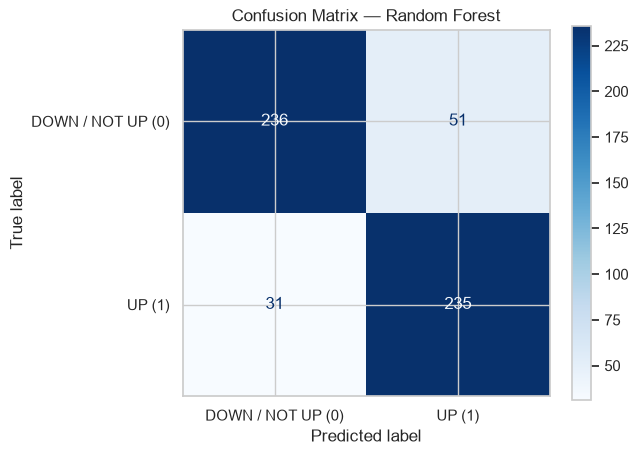

In [15]:
best_model_name = "Random Forest"
best_model = trained_models[best_model_name]
best_predictions = best_model.predict(X_test_scaled)
best_probabilities = best_model.predict_proba(X_test_scaled)[:, 1]

print("Primary model for confusion-matrix analysis:", best_model_name)
print("\nClassification report:")
print(classification_report(
    y_test, best_predictions,
    labels=[0, 1],
    target_names=["DOWN / NOT UP", "UP"],
    zero_division=0
))

cm = confusion_matrix(y_test, best_predictions, labels=[0, 1])
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["DOWN / NOT UP (0)", "UP (1)"]
)
disp.plot(cmap="Blues", values_format="d")
plt.title(f"Confusion Matrix — {best_model_name}")
plt.tight_layout()
plt.show()

In [16]:
print("Accuracy:", round(accuracy_score(y_test, best_predictions), 4))
print("Precision:", round(precision_score(y_test, best_predictions, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, best_predictions, zero_division=0), 4))
print("F1-score:", round(f1_score(y_test, best_predictions, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, best_probabilities), 4))

Accuracy: 0.8517
Precision: 0.8217
Recall: 0.8835
F1-score: 0.8514
ROC-AUC: 0.9147


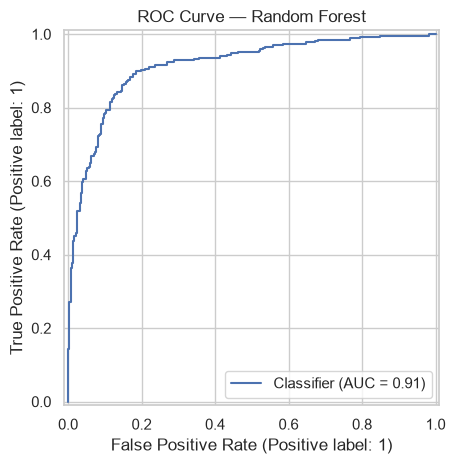

In [17]:
RocCurveDisplay.from_predictions(y_test, best_probabilities)
plt.title(f"ROC Curve — {best_model_name}")
plt.tight_layout()
plt.show()

## 11. Random Forest feature importance
Feature importance offers one way to inspect which engineered variables the Random Forest relied on. It describes model behaviour, not proof of causation.

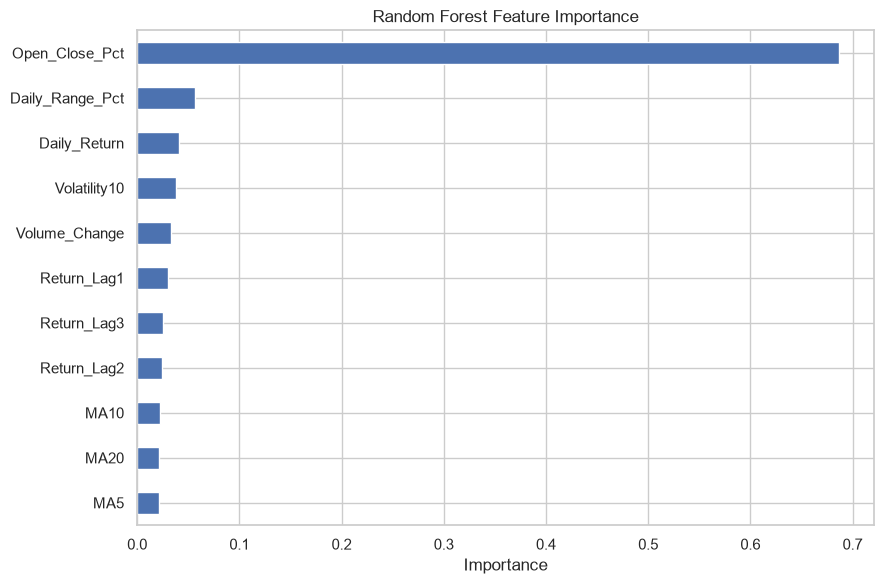

,Importance
Open_Close_Pct,0.686601
Daily_Range_Pct,0.056640
Daily_Return,0.040832
Volatility10,0.038351
Volume_Change,0.032746
Return_Lag1,0.030564
Return_Lag3,0.024985
Return_Lag2,0.023992
MA10,0.022064
MA20,0.021825


In [18]:
rf_model = trained_models["Random Forest"]
importances = pd.Series(rf_model.feature_importances_, index=feature_columns).sort_values()

plt.figure(figsize=(9, 6))
importances.plot(kind="barh")
plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

display(importances.sort_values(ascending=False).to_frame("Importance"))

## 12. Predict the next direction from the latest available row
This cell produces a demonstration prediction from the latest feature row using the Random Forest model. It is not a recommendation to buy or sell. The model should be retrained and evaluated on newer data before any serious use.

In [19]:
latest_features = model_df[feature_columns].iloc[[-1]]
latest_scaled = scaler.transform(latest_features)
next_direction = best_model.predict(latest_scaled)[0]
next_up_probability = best_model.predict_proba(latest_scaled)[0, 1]

print("Latest feature date:", model_df["Date"].iloc[-1].date())
print("Predicted next trading-day direction:", "UP" if next_direction == 1 else "DOWN / NOT UP")
print("Model estimated probability of UP:", round(float(next_up_probability), 4))

Latest feature date: 2015-01-02
Predicted next trading-day direction: DOWN / NOT UP
Model estimated probability of UP: 0.2997


## 13. Conclusion
This project demonstrates a complete predictive analytics workflow on real-world financial time-series data:

1. Data collection and cleaning
2. Exploratory data analysis and IQR-based outlier inspection
3. Feature engineering using lagged returns, moving averages and volatility
4. Binary target creation for next-day market direction
5. Chronological train-test split
6. Standardisation without fitting the scaler on test data
7. Comparison of Logistic Regression, SVM, KNN and Random Forest
8. Evaluation using a confusion matrix, precision, recall, F1-score and ROC-AUC

### Limitations
Stock-market movement depends on many factors not represented by these features. A good historical test score does not guarantee future performance. The data is observational, the target is noisy, and this model is for academic demonstration only.

### Dataset source
NIFTY 50 historical CSV dataset (GitHub repository):  
https://github.com/Hareeshkesavan/Stock-Market-Dataset/blob/main/Nifty%2050%20Historical%20Data.csv